# Fashion MNIST dataset for Image Classification using LeNet and AlexNet

## INTRODUCTION
The task of Image Classification of FASHION MNIST dataset using CNN models is undertaken in this notebook. Image Classification is assigning each image a specific class by analyzing the pixel values or image vectors. Classification can Supervised or Unsupervised, and in out case Supervised learning is dealt with where we have labels or ground-truth per image. For the task, Fashion MNIST dataset has been chosen that are Zalando's article images containing 10 classes namely: <br>

0 T-shirt/top<br>
1 Trouser<br>
2 Pullover<br>
3 Dress<br>
4 Coat<br>
5 Sandal<br>
6 Shirt<br>
7 Sneaker<br>
8 Bag<br>
9 Ankle boot<br>

The dataset has large number of samples and has been used to train many Machine Learning models. The dataset is chosen since it is easy to understand and implement and requires less computation of time and GPU because the images have a small size of 28x28 pixels only. The dataset contains 70,000 with 60,000 images for training and 10,000 images for testing and is balanced with equal number of images per class. This dataset can also be used as a replacement to the MNIST dataset that contains hand written digits from 0 to 9.<br>

Python library Keras has been utilized for the task of Image Classification since they allow easy access to data without downloading and allows flexible access of the features.



### Import Required Libraries, Split the data and Display

In [ ]:
#import libraries
import numpy as np
import matplotlib.pyplot as plt
from keras.callbacks import ModelCheckpoint
from keras.datasets import fashion_mnist
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Activation, ZeroPadding2D
from keras.models import Sequential
from keras.utils import np_utils
from keras.applications.vgg16 import VGG16
import tensorflow as tf
import time

Numpy library is used for incorporaying mathematical functions. <br>
Matplotlib is used for generating visualizations <br>
Keras is used to import the fashion_mnist dataset along with layers of the CNN

### Splitting the dataset

In [ ]:
#split data into train and test
dataset = fashion_mnist.load_data()
(X_train, y_train), (X_test, y_test) = dataset
print("X_train original shape", X_train.shape)
print("y_train original shape", y_train.shape)
print("X_test original shape", X_test.shape)
print("y_test original shape", y_test.shape)

4431872/4422102 [==============================] - 0s 0us/step
X_train original shape (60000, 28, 28)
y_train original shape (60000,)
X_test original shape (10000, 28, 28)
y_test original shape (10000,)


The dataset is loaded and split into test and train set. The number and size of train and test images is shown. The images are of size 28x28 with 60,000 for train and 10,000 for test. 'y' contains the labels for test and train. 

### Exploring the dataset

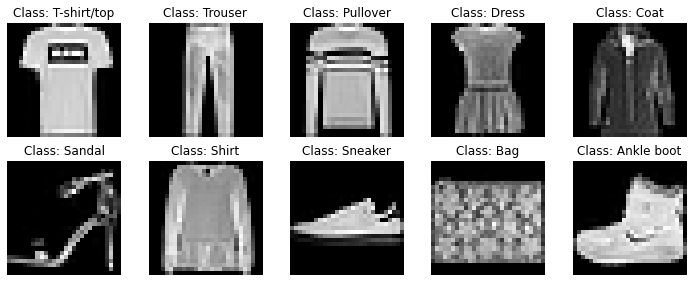

In [ ]:
#assign class labels
class_labels_dict = {0:"T-shirt/top",1:"Trouser",2:"Pullover",3:"Dress",4:"Coat",5:"Sandal",6:"Shirt",7:"Sneaker",8:"Bag",9:"Ankle boot"}

#plot dataset images
fig = plt.figure(figsize=(10,4))

for i in range(10):
    plt.subplot(2,5,i+1)
    img = X_train[y_train == i][0]
    plt.imshow(img, cmap='gray', interpolation='none')
    plt.title("Class: {}".format(class_labels_dict[i]))
    plt.axis('off')
    
plt.tight_layout()

The above code shows the first 10 images in the training dataset along with their labels. 
### Preprocess the data

In [ ]:
# Normalizing the dataset
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

X_train /= 255
X_test /= 255

#converting the normalized dataset into one-hot-encoded data
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

We convert the pixels into float and since 28x28=784 we get a vector of length 784.<br>
The pixel values can range from [0-255] and so we normalise the inputs so that pixel values are in the [0-1] range rather than [0-255] by dividing eaxh pixel value by 255.
<br>
For the label one Hot encoding is performed by converting the pixels into binary vectors to remove the effect of categorical biasness. Since we have 10 classes the binary vector has a length of 10.


## Create the Model


###LeNet

In [ ]:
#Building the AlexNet algorithm for compiling and training
model = Sequential()
model.add(Conv2D(30, kernel_size=2, activation='relu', padding='same', input_shape=(28,28,1)))
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))
model.add(Conv2D(20, kernel_size=2, activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))
model.add(Flatten())
model.add(Dense(1000, activation='relu'))
model.add(Dense(10, activation='softmax'))

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 30)        150       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 14, 14, 30)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 13, 13, 20)        2420      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 6, 6, 20)         0         
 2D)                                                             
                                                                 
 flatten (Flatten)           (None, 720)               0         
                                                                 
 dense (Dense)               (None, 1000)              7

LeNet model is the first CNN architecture and is very simple and basic. It was proposed in 1989 by Yann LeCun et al. The model has 2 convolution and 2 pooling layers. In the end we have 2 fully connected layers and softmax loss. The total parameters are 733,580.<br>


In the code below we train the model with different batchsize and epochs to see the effect it has on accuracy. The model is complied with categorical crossentropy loss, Adam optimizer and Accuracy metric. 
<br>
#### Test 1 for LeNet: Batchsize = 64, Epochs = 10

In [ ]:
#Compiling the build algorithm for training
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
#Calculating the consumed time and training the model
start_time = time.time()
history = model.fit(X_train, y_train, epochs=10, batch_size=64, verbose=True, validation_split=0.25)
print("--- %s seconds ---" % (time.time() - start_time))

Epoch 1/10
704/704 [==============================] - 16s 10ms/step - loss: 0.4807 - accuracy: 0.8271 - val_loss: 0.3617 - val_accuracy: 0.8651
Epoch 2/10
704/704 [==============================] - 7s 10ms/step - loss: 0.3165 - accuracy: 0.8842 - val_loss: 0.3116 - val_accuracy: 0.8851
Epoch 3/10
704/704 [==============================] - 6s 9ms/step - loss: 0.2762 - accuracy: 0.8974 - val_loss: 0.2931 - val_accuracy: 0.8945
Epoch 4/10
704/704 [==============================] - 6s 9ms/step - loss: 0.2456 - accuracy: 0.9092 - val_loss: 0.2592 - val_accuracy: 0.9045
Epoch 5/10
704/704 [==============================] - 6s 9ms/step - loss: 0.2223 - accuracy: 0.9162 - val_loss: 0.2621 - val_accuracy: 0.9041
Epoch 6/10
704/704 [==============================] - 6s 8ms/step - loss: 0.2020 - accuracy: 0.9248 - val_loss: 0.2449 - val_accuracy: 0.9107
Epoch 7/10
704/704 [==============================] - 6s 8ms/step - loss: 0.1821 - accuracy: 0.9316 - val_loss: 0.2581 - val_accuracy: 0.9065
Epo

The model gives 95% accuracy and 91.56% validation accuracy for Batchsize = 64, Epochs = 10 in 71 seconds.
<br>
#### Test 2 for LeNet: Batchsize = 128, Epochs = 10

In [ ]:
#Calculating the consumed time and training the model
start_time = time.time()
history = model.fit(X_train, y_train, epochs=10, batch_size=128, verbose=True, validation_split=0.25)
print("--- %s seconds ---" % (time.time() - start_time))

Epoch 1/10
352/352 [==============================] - 4s 11ms/step - loss: 0.0030 - accuracy: 0.9994 - val_loss: 0.5566 - val_accuracy: 0.9147
Epoch 2/10
352/352 [==============================] - 4s 10ms/step - loss: 7.7977e-04 - accuracy: 1.0000 - val_loss: 0.5687 - val_accuracy: 0.9163
Epoch 3/10
352/352 [==============================] - 4s 10ms/step - loss: 4.4996e-04 - accuracy: 1.0000 - val_loss: 0.5838 - val_accuracy: 0.9175
Epoch 4/10
352/352 [==============================] - 4s 10ms/step - loss: 3.3480e-04 - accuracy: 1.0000 - val_loss: 0.5945 - val_accuracy: 0.9181
Epoch 5/10
352/352 [==============================] - 4s 10ms/step - loss: 2.6805e-04 - accuracy: 1.0000 - val_loss: 0.6102 - val_accuracy: 0.9183
Epoch 6/10
352/352 [==============================] - 4s 10ms/step - loss: 2.2138e-04 - accuracy: 1.0000 - val_loss: 0.6192 - val_accuracy: 0.9186
Epoch 7/10
352/352 [==============================] - 4s 10ms/step - loss: 1.8058e-04 - accuracy: 1.0000 - val_loss: 0.630

The model gives 100% accuracy and 91.87% validation accuracy for Batchsize = 128, Epochs = 10. Both the accuracies have increased with increase in batchsize in 41 seconds.
<br>
#### Test 3 for LeNet: Batchsize = 64, Epochs = 15

In [ ]:
#Calculating the consumed time and training the model
start_time = time.time()
history = model.fit(X_train, y_train, epochs=15, batch_size=64, verbose=True, validation_split=0.25)
print("--- %s seconds ---" % (time.time() - start_time))

Epoch 1/15
704/704 [==============================] - 6s 9ms/step - loss: 0.0397 - accuracy: 0.9897 - val_loss: 0.4803 - val_accuracy: 0.9051
Epoch 2/15
704/704 [==============================] - 6s 9ms/step - loss: 0.0288 - accuracy: 0.9901 - val_loss: 0.5755 - val_accuracy: 0.9125
Epoch 3/15
704/704 [==============================] - 7s 9ms/step - loss: 0.0103 - accuracy: 0.9972 - val_loss: 0.5920 - val_accuracy: 0.9119
Epoch 4/15
704/704 [==============================] - 6s 9ms/step - loss: 0.0122 - accuracy: 0.9961 - val_loss: 0.5975 - val_accuracy: 0.9109
Epoch 5/15
704/704 [==============================] - 8s 12ms/step - loss: 0.0158 - accuracy: 0.9949 - val_loss: 0.6142 - val_accuracy: 0.9117
Epoch 6/15
704/704 [==============================] - 7s 10ms/step - loss: 0.0139 - accuracy: 0.9955 - val_loss: 0.6014 - val_accuracy: 0.9154
Epoch 7/15
704/704 [==============================] - 6s 9ms/step - loss: 0.0032 - accuracy: 0.9992 - val_loss: 0.6458 - val_accuracy: 0.9125
Epoc

The model gives 99.98% accuracy and 91.35% validation accuracy for Batchsize = 65, Epochs = 15. The accuracy is slightly less with 15 Epochs in 142 seconds.
<br>

#### Evaluating the trained model

In [ ]:
#Calculating the consumed time and evaluating the model
start_time = time.time()
metrics = model.evaluate(X_test, y_test, verbose=True)
print("--- %s seconds ---" % (time.time() - start_time))

313/313 [==============================] - 1s 4ms/step - loss: 0.7525 - accuracy: 0.9102
--- 1.3456377983093262 seconds ---


The model is tested resulting in 91.02% accuracy in 1.34 seconds.
### Visualize the Results

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


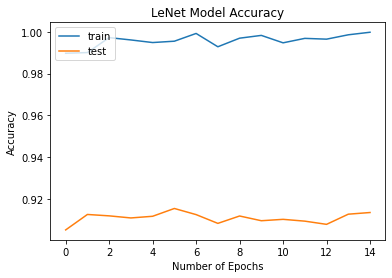

In [ ]:
print(history.history.keys())
# Accuracy Visualization
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("LeNet Model Accuracy")
plt.ylabel('Accuracy')
plt.xlabel('Number of Epochs')
plt.legend(['train', 'test'], loc='upper left')
plt.show()


The graph shows that the accuracy remains above 99% and the validation accuracy fluctuates between 90% to 92%, with the increase in number of Epochs.

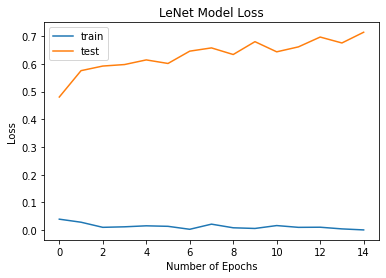

In [ ]:
# Loss Visualization
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("LeNet Model Loss")
plt.ylabel('Loss')
plt.xlabel('Number of Epochs')
plt.legend(['train', 'test'], loc='upper left')
plt.show()


The graph shows that the loss remains below 1% while decreasing and the validation loss tends to increase with the increase in number of Epochs.
#AlexNet

### Building the network

In [ ]:
#Building the AlexNet algorithm for compiling and training
model2 = Sequential()
model2.add(Conv2D(filters=32,kernel_size=(3,3),strides=(1,1),input_shape=(28,28,1), activation='relu'))
model2.add(MaxPooling2D(pool_size=(2,2),strides=(2,2)))
model2.add(Conv2D(64,(3,3),padding='same',activation='relu'))
model2.add(MaxPooling2D(pool_size=(2,2),strides=(2,2)))
model2.add(Conv2D(64,(3,3),padding='same',activation='relu'))
model2.add(Conv2D(96,(3,3),padding='same',activation='relu'))
model2.add(Conv2D(64,(3,3),padding='same',activation='relu'))
model2.add(MaxPooling2D(pool_size=(2,2),strides=(2,2)))

model2.add(Flatten())
model2.add(Dense(4096, activation='relu'))
model2.add(Dense(4096, activation='relu'))
model2.add(Dense(10,activation='softmax'))


In [ ]:
model2.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 13, 13, 32)       0         
 2D)                                                             
                                                                 
 conv2d_3 (Conv2D)           (None, 13, 13, 64)        18496     
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 6, 6, 64)         0         
 2D)                                                             
                                                                 
 conv2d_4 (Conv2D)           (None, 6, 6, 64)          36928     
                                                                 
 conv2d_5 (Conv2D)           (None, 6, 6, 96)         

AlexNet model is the second CNN architecture and is also very simple and basic. The layers are more than LeNet. It was proposed in 2012 by  Alex Krizhevsky. The model has 5 convolution and 3 pooling layers. In the end we have 3 fully connected layers and softmax loss. The total parameters are 19,352,170.<br>


In the code below we train the model with different batchsize and epochs to see the effect it has on accuracy. The model is complied with categorical crossentropy loss, Adam optimizer and Accuracy metric. 
<br>
### Test 1 for AlexNet: Batchsize = 64, Epochs = 10

#### Compiling the network for training

In [ ]:
#Compiling the build algorithm for training
model2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

#### Trainin the network

In [ ]:
#Calculating the consumed time and training the model
start_time = time.time()
history2 = model2.fit(X_train, y_train, epochs=10, batch_size=64, verbose=True, validation_split=0.20)
print("--- %s seconds ---" % (time.time() - start_time))

Epoch 1/10
750/750 [==============================] - 19s 23ms/step - loss: 0.5082 - accuracy: 0.8099 - val_loss: 0.3805 - val_accuracy: 0.8544
Epoch 2/10
750/750 [==============================] - 17s 23ms/step - loss: 0.3197 - accuracy: 0.8823 - val_loss: 0.2944 - val_accuracy: 0.8904
Epoch 3/10
750/750 [==============================] - 18s 24ms/step - loss: 0.2678 - accuracy: 0.9019 - val_loss: 0.2934 - val_accuracy: 0.8942
Epoch 4/10
750/750 [==============================] - 18s 24ms/step - loss: 0.2436 - accuracy: 0.9103 - val_loss: 0.2659 - val_accuracy: 0.9052
Epoch 5/10
750/750 [==============================] - 17s 23ms/step - loss: 0.2182 - accuracy: 0.9185 - val_loss: 0.2885 - val_accuracy: 0.8943
Epoch 6/10
750/750 [==============================] - 17s 23ms/step - loss: 0.2021 - accuracy: 0.9250 - val_loss: 0.2653 - val_accuracy: 0.9024
Epoch 7/10
750/750 [==============================] - 17s 23ms/step - loss: 0.1891 - accuracy: 0.9297 - val_loss: 0.2477 - val_accuracy:

The model gives 94.71% accuracy and 91.47% validation accuracy for Batchsize = 64, Epochs = 15. The training time is 203 seconds.
<br>
#### Test 2 for AlexNet: Batchsize = 128, Epochs = 10

In [ ]:
#Calculating the consumed time and training the model
start_time = time.time()
history2 = model2.fit(X_train, y_train, epochs=10, batch_size=128, verbose=True, validation_split=0.20)
print("--- %s seconds ---" % (time.time() - start_time))

Epoch 1/10
375/375 [==============================] - 13s 33ms/step - loss: 0.0855 - accuracy: 0.9662 - val_loss: 0.3032 - val_accuracy: 0.9155
Epoch 2/10
375/375 [==============================] - 12s 31ms/step - loss: 0.0707 - accuracy: 0.9723 - val_loss: 0.3402 - val_accuracy: 0.9169
Epoch 3/10
375/375 [==============================] - 12s 32ms/step - loss: 0.0619 - accuracy: 0.9749 - val_loss: 0.3543 - val_accuracy: 0.9170
Epoch 4/10
375/375 [==============================] - 12s 33ms/step - loss: 0.0634 - accuracy: 0.9760 - val_loss: 0.3412 - val_accuracy: 0.9136
Epoch 5/10
375/375 [==============================] - 12s 31ms/step - loss: 0.0615 - accuracy: 0.9771 - val_loss: 0.3876 - val_accuracy: 0.9116
Epoch 6/10
375/375 [==============================] - 12s 31ms/step - loss: 0.0552 - accuracy: 0.9786 - val_loss: 0.3584 - val_accuracy: 0.9158
Epoch 7/10
375/375 [==============================] - 12s 33ms/step - loss: 0.0534 - accuracy: 0.9803 - val_loss: 0.4203 - val_accuracy:

The model gives 98.54% accuracy and 91.49% validation accuracy for Batchsize = 128, Epochs = 10. The training time is 120 seconds. Increasing batchsize reduces the training time and improves the accuracy.
<br>
#### Test 3 for AlexNet: Batchsize = 64, Epochs = 15

In [ ]:
#Calculating the consumed time and training the model
start_time = time.time()
history2 = model2.fit(X_train, y_train, epochs=15, batch_size=64, verbose=True, validation_split=0.20)
print("--- %s seconds ---" % (time.time() - start_time))

Epoch 1/15
750/750 [==============================] - 17s 23ms/step - loss: 0.1084 - accuracy: 0.9608 - val_loss: 0.3877 - val_accuracy: 0.9018
Epoch 2/15
750/750 [==============================] - 17s 22ms/step - loss: 0.0828 - accuracy: 0.9698 - val_loss: 0.3892 - val_accuracy: 0.9084
Epoch 3/15
750/750 [==============================] - 17s 23ms/step - loss: 0.0699 - accuracy: 0.9746 - val_loss: 0.3691 - val_accuracy: 0.9109
Epoch 4/15
750/750 [==============================] - 17s 22ms/step - loss: 0.0676 - accuracy: 0.9760 - val_loss: 0.3815 - val_accuracy: 0.9065
Epoch 5/15
750/750 [==============================] - 17s 22ms/step - loss: 0.0614 - accuracy: 0.9782 - val_loss: 0.4240 - val_accuracy: 0.9045
Epoch 6/15
750/750 [==============================] - 18s 24ms/step - loss: 0.0506 - accuracy: 0.9820 - val_loss: 0.4667 - val_accuracy: 0.9104
Epoch 7/15
750/750 [==============================] - 17s 23ms/step - loss: 0.0557 - accuracy: 0.9797 - val_loss: 0.4171 - val_accuracy:

The model gives 98.31% accuracy and 90.40% validation accuracy for Batchsize = 64, Epochs = 15. The accuracy is slightly less with 15 Epochs in 262 seconds. Increasing batchsize increases training time.
<br>

#### Evaluating the trained model

In [ ]:
#Calculating the consumed time and evaluating the model
start_time = time.time()
metrics = model2.evaluate(X_test, y_test, verbose=True)
print("--- %s seconds ---" % (time.time() - start_time))

313/313 [==============================] - 2s 8ms/step - loss: 0.5896 - accuracy: 0.9064
--- 2.500492572784424 seconds ---


The model is tested resulting in 90.64% accuracy in 2.5 seconds.
### Visualize the Results

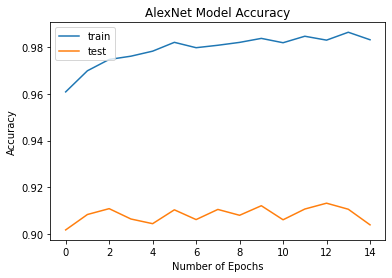

In [ ]:
# print(history.history.keys())
# AlexNet Accuracy 
plt.plot(history2.history['accuracy'])
plt.plot(history2.history['val_accuracy'])
plt.title("AlexNet Model Accuracy")
plt.ylabel('Accuracy')
plt.xlabel('Number of Epochs')
plt.legend(['train', 'test'], loc='upper left')
plt.show()


The graph shows that the accuracy remains above 96% and the validation accuracy fluctuates between 90% to 91%, with the increase in number of Epochs.

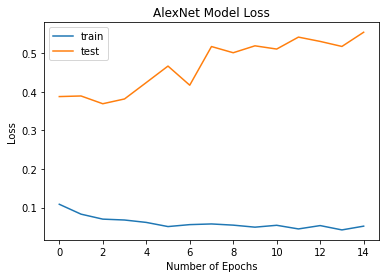

In [ ]:
# Loss Visualization
plt.plot(history2.history['loss'])
plt.plot(history2.history['val_loss'])
plt.title("AlexNet Model Loss")
plt.ylabel('Loss')
plt.xlabel('Number of Epochs')
plt.legend(['train', 'test'], loc='upper left')
plt.show()


The graph shows that the loss decreases to less than 10%  and the validation loss fluctuates and tends to increase with the increase in number of Epochs.

#Comparison

For the task of image classification on FASHION MNIST dataset, LeNet and AlexNet were deployed. The purpose for choosing the model being:


*   Easy to understand and use 
*   Less Deep with less number of parameters
*   VGG16 model was tried but is trained for RBG and may not give good results for a gray scale data set. Additionally, models proposed after AlexNet require images with a large size that is 32x32 minimum for VGG16 whereas, out dataset is of 28x28 pixels.

The 2 models were tested by varying batchsize and Epochs count. <br>

*   LeNet


1.   Batchsize=64, Epochs=10, Accuracy=91.56%, Training time=71s
2.   Batchsize=64, Epochs=15, Accuracy=91.35%, Training time=142s
3.   Batchsize=128, Epochs=10, Accuracy=91.87%, Training time=41s


*   AlexNet

1.   Batchsize=64, Epochs=10, Accuracy=94.71%, Training time=203s
2.   Batchsize=64, Epochs=15, Accuracy=98.31%, Training time=262s
3.   Batchsize=128, Epochs=10, Accuracy=98.54%, Training time=120s<br>



#Conclusion



Overall, AlexNet gives better results on FASHION MNIST dataset the reason being a deeper model which learns the features in more detail, however, the training time of AlexNet is higher due to the same reason along with the number of parameters. <br>Even though the accuracy is quite high the validation accuracy remains around 90% to 91%, drop-out layers can be used in the work to add regularization and the model can be made more deep. Data Augmentation can be applied to increase the number of training samples which can help in more better training of the model.

